# Tutorial T03 – pandas, librosa (& scikit-learn)
*MIR & ML for Audio · TU Berlin · WiSe 2026/27*

| Block | Topic |
|---|---|
| 0 | Setup |
| 1 | pandas – tables in Python |
| 2 | Open Warngler: Inspect the data before you code |
| 3 | librosa – main feature package in Python |
| 4 | Task: tempo estimation vs. Beatport BPM |
| 5 | scikit-learn – machine learning in Python *(if time allows)* |

In [1]:
# import standard packages you'll need

import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(sys.executable)

# ─ add your own additional imports here:
import librosa
import librosa.display
from IPython.display import Audio, display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

/home/hallvard/miniforge3/envs/mirml/bin/python


In [2]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"   # ← name of your corpus folder
# ─────────────────────────────────────────────────────────────────────────
SESSION = "T03"
PREVIEW_DIR = CORPUS_DIR / "previews"
OUTPUT_DIR = Path("output") / SESSION      # results of this session
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CORPUS_DIR.is_dir(), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))
print(CHART_CSV)

data/nu-disco-disco/Nu_Disco_Disco.csv


---
## 1 · pandas – tables in Python

| Excel | pandas |
|---|---|
| Sheet | `DataFrame` (table) |
| Column | `Series` – `df["bpm"]` |
| Row numbers | index – `df.index` |
| Open file | `pd.read_csv("file.csv")` |
| Filter | `df[df["bpm"] > 140]` |
| Sort | `df.sort_values("bpm")` |
| New column with a formula | `df["duration_min"] = df["duration_ms"] / 60_000` |
| COUNTIF / AVERAGE | `(df["bpm"] > 140).sum()`, `df["bpm"].mean()` |
| Pivot table | `df.groupby("year")["bpm"].median()` |
| Count values | `df["label"].value_counts()` |
| VLOOKUP | `df.merge(other, on="id")`, `df["id"].map(lookup)` |
| Save as | `df.to_csv("file.csv", index=False)` |

In [3]:
df_charts = pd.read_csv(CHART_CSV) # load your csv as df (DataFrame)

print(df_charts.shape)   # (rows, columns)
df_charts.head(10)         # first 5 rows

(3813, 14)


,year,rank,points,days_charted,beatport_track_id,title,mix,artist,label,duration_ms,subgenre,isrc,bpm,release_date
0,2019,1,11313,116,12210204,Emotion,Extended Mix,Purple Disco Machine,Club Sweat,369674.0,NaN,AUDCB1701419,122.0,2019-07-19
1,2019,2,11107,116,12360939,Express Yourself,Original Mix,Mark Lower,Salted Music,379000.0,NaN,USATE1916201,122.0,2019-08-02
2,2019,3,10736,116,12310558,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2019,4,10490,116,12441066,Heaven feat. Andreya Triana,Mousse T.'s Disco Shizzle Extended Remix,"The Vision, Andreya Triana, Mousse T.",Defected,425290.0,NaN,GBCPZ1915981,120.0,2019-08-30
4,2019,5,10130,102,12521466,Joys,Purple Disco Machine Extended Remix,"Roberto Surace, Purple Disco Machine",Defected,397775.0,NaN,GBCPZ1916565,123.0,2019-09-20
5,2019,6,9654,116,11137506,Get Down Tonight,Original Mix,"Marvin Aloys, Rough Traders, 5&Dime",Greenmountain,351221.0,NaN,GBMA21818360,121.0,2018-11-09
6,2019,7,9467,116,9323977,Body Funk,Original Mix,Purple Disco Machine,Club Sweat,443488.0,NaN,AUDCB1701030,122.0,2017-05-25
7,2019,8,9430,116,12268840,Heaven feat. Andreya Triana,Original Mix,"The Vision, Andreya Triana",Defected,298416.0,NaN,GBCPZ1915974,120.0,2019-07-19
8,2019,9,9366,116,10465529,Dished (Male Stripper),Extended Mix,Purple Disco Machine,Club Sweat,504112.0,NaN,AUDCB1701157,123.0,2018-04-30
9,2019,10,9280,116,12416613,Falling Deep In Love,"Joey Negro 12"" Disco Blend","Horse Meat Disco, Kathy Sledge, Joey Negro",Glitterbox Recordings,424053.0,NaN,GBCPZ1916023,120.0,2019-08-23


In [4]:
df_charts.info()         # columns, dtypes and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 3813 entries, 0 to 3812
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               3813 non-null   int64  
 1   rank               3813 non-null   int64  
 2   points             3813 non-null   int64  
 3   days_charted       3813 non-null   int64  
 4   beatport_track_id  3813 non-null   int64  
 5   title              3459 non-null   str    
 6   mix                3459 non-null   str    
 7   artist             3459 non-null   str    
 8   label              3459 non-null   str    
 9   duration_ms        3459 non-null   float64
 10  subgenre           52 non-null     str    
 11  isrc               3447 non-null   str    
 12  bpm                3459 non-null   float64
 13  release_date       3459 non-null   str    
dtypes: float64(2), int64(5), str(7)
memory usage: 417.2 KB


In [5]:
# Select columns, filter rows, sort
cols = ["year", "rank", "artist", "title", "bpm"]
top10 = df_charts[df_charts["rank"] <= 10]                  # boolean mask = filter
top10[cols].sort_values("bpm", ascending=False).head(10)

,year,rank,artist,title,bpm
3029,2023,9,"Syzz, Nora Van Elken",Disco Inferno,126.0
399,2020,7,Disco Incorporated,Makusa,124.0
1335,2021,7,"The Sponges, Sgt Slick",Gotta Move On,124.0
2210,2022,9,"Babert, Mell Hall",Can't Stop Now,124.0
394,2020,2,Algrthm,On My Mind,123.0
4,2019,5,"Roberto Surace, Purple Disco Machine",Joys,123.0
393,2020,1,"Roberto Surace, Purple Disco Machine",Joys,123.0
8,2019,9,Purple Disco Machine,Dished (Male Stripper),123.0
1329,2021,1,"Diplo, SIDEPIECE, Purple Disco Machine",On My Mind,123.0
1331,2021,3,"Mylo, Claptone, Purple Disco Machine",Drop The Pressure,123.0


In [6]:
# New column, summary per group, value counts
df_charts["duration_min"] = (df_charts["duration_ms"] / 60_000).round(2)
print(df_charts.groupby("year")["duration_min"].median())

year
2019    6.330
2020    6.085
2021    5.840
2022    5.670
2023    5.650
Name: duration_min, dtype: float64


In [7]:
# want to save the new column? -> Save as (new) csv, index=False to prevent an index duplicate when reloading the table
df_charts.to_csv(OUTPUT_DIR / "charts_T03.csv", index=False)

**Your turn** – Which are the 5 **longest** tracks in your corpus?

In [16]:
# your code
df_unique = df_charts.drop_duplicates("beatport_track_id")
cols = ["year", "artist", "title", "duration_min"]
df_unique[cols].sort_values("duration_min", ascending=False).head(5)

,year,artist,title,duration_min
629,2020,"AC Soul Symphony, Dave Lee ZR, JN",AC Soul Symphony - Manhattan Skyline,11.12
1795,2021,"Soulwax, Sylvester",You Make Me Feel (Mighty Real),10.98
2431,2022,"Louie Vega, Karen Harding, David Morales",Free to Love,10.78
585,2020,"Amy Douglas, Horse Meat Disco, Dames Brown, Da...",Message To The People feat. Amy Douglas feat. ...,10.78
605,2020,"Anane, Louie Vega",Get On The Funk Train,10.65


---
## 2 look at the data before you code
Open the chart CSV in **Data Wrangler / Open Wrangler** and inspect it before working with scripts:
- What do the columns contain? Which values are missing?
- Sort `bpm` ascending: is the slowest tempo plausible for your genre?

In [17]:
# Listen to the slowest track 
                        # (filtered by Top 100 only) & only rows with bpm > 0 .nsmallest(number of entries, column)."select first row"
slowest = df_charts[(df_charts["rank"] <= 100) & (df_charts["bpm"] > 0)].nsmallest(1, "bpm") .iloc[0]

print(slowest["artist"], "–", slowest["title"], "|", slowest["bpm"], "BPM")
Audio(filename=PREVIEW_DIR / f"{int(slowest['beatport_track_id'])}.mp3")

Sister Sledge, Dimitri From Paris – Lost In Music | 81.0 BPM


---
## 3 · librosa – audio analysis in Python
Key defaults: `librosa.load()` resamples to **22 050 Hz** and downmixes to **mono** (`sr=None`, `mono=False` keep the original). Frames: `n_fft=2048`, `hop_length=512` → one frame every 512 / 22 050 Hz ≈ 23 ms.

Example functions: 
| Module | What it does | Examples |
|---|---|---|
| core / I/O | load, resample, transform | `load`, `stft`, `cqt`, `amplitude_to_db` |
| `feature` | frame-level features | `mfcc`, `spectral_centroid`, `spectral_flatness`, `rms`, `zero_crossing_rate`, `chroma_cqt`, `tempo`, `tempogram` |
| `onset` | onset detection | `onset_strength`, `onset_detect` |
| `segment` | structure analysis | `recurrence_matrix`, `agglomerative` |
| `display` | plots | `waveshow`, `specshow` |

/home/hallvard/miniforge3/envs/mirml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(2646000,) 22050 → 120.0 s


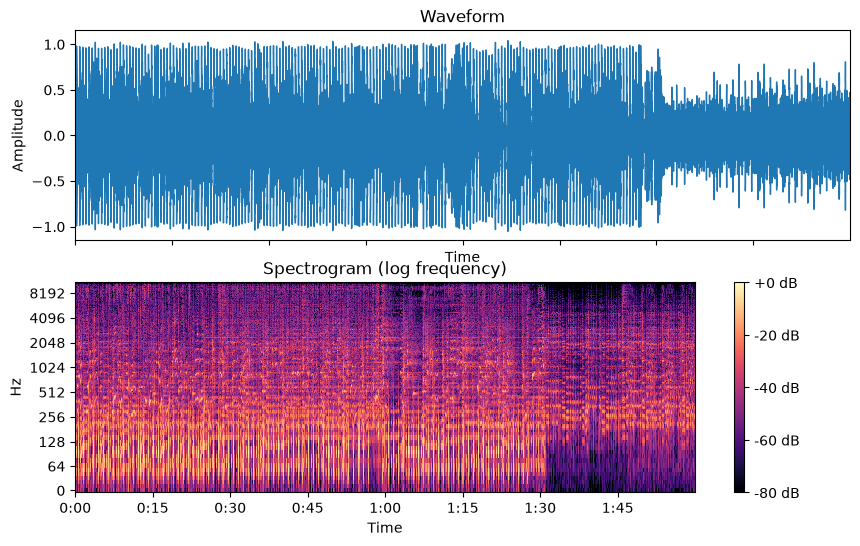

In [18]:
# Load one preview and look at it: waveform and spectrogram
path = PREVIEW_DIR / f"{int(slowest['beatport_track_id'])}.mp3"
y, sr = librosa.load(path)                                   # mono, 22 050 Hz as default
print(y.shape, sr, f"→ {len(y) / sr:.1f} s")

S_db = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)   # STFT magnitude in dB

# plot waveform and spectrogram
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
librosa.display.waveshow(y, sr=sr, ax=ax1)
img = librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="log", ax=ax2)
ax1.set(title="Waveform", ylabel="Amplitude")
ax2.set(title="Spectrogram (log frequency)", xlabel="Time")
fig.colorbar(img, ax=ax2, format="%+2.0f dB")
plt.show()

---
## 4 task: librosa tempo estimation vs. Beatport BPM
`librosa.feature.tempo()` estimates one global tempo per track: onset strength curve → autocorrelation → most likely periodicity, weighted by a prior around `start_bpm`.
Typical error: **octave errors** – half or double tempo (e.g. 87 vs. 174 BPM). Check them on the slowest and fastest tracks of your corpus.

In [19]:
# 4.1 Select the 10 % slowest Top-100 tracks with a preview (bpm > 0 excludes NaN and the placeholder 0)
tracks = df_charts[(df_charts["rank"] <= 100) & (df_charts["bpm"] > 0)].drop_duplicates("beatport_track_id")
tracks = tracks[[(PREVIEW_DIR / f"{int(i)}.mp3").exists() for i in tracks["beatport_track_id"]]]

# select a percentage of the list
n = round(number=0.10 * len(tracks))   

slow = tracks.nsmallest(n, "bpm")
slow[["artist", "title", "bpm"]].head()

,artist,title,bpm
13,"Sister Sledge, Dimitri From Paris",Lost In Music,81.0
433,"Purple Disco Machine, Sophie and the Giants",Hypnotized,108.0
2297,W.O.L.F.,STAYIN ALIVE,111.0
31,"JKriv, Adeline (US)",Yo Love feat. Adeline,112.0
58,"Monolink, Purple Disco Machine",Take Me Home,115.0


In [20]:
# 4.2 parameters for tempo estimation
HOP_LENGTH = 512     # samples between frames of the onset curve: 512 @ 22.05 kHz ≈ 23 ms time resolution
AC_SIZE = 8.0        # length of the autocorrelation window in s – should cover several bars
MAX_TEMPO = 200.0    # upper limit of the estimate in BPM
START_BPM = 100.0    # prior: the estimator prefers tempi near this value 

def estimate_tempo(path):
    y, sr = librosa.load(path)
    onset_env = librosa.onset.onset_strength(y=y, sr=sr, hop_length=HOP_LENGTH)
    return librosa.feature.tempo(onset_envelope=onset_env, sr=sr, hop_length=HOP_LENGTH,
                                 ac_size=AC_SIZE, max_tempo=MAX_TEMPO, start_bpm=START_BPM)[0]

# try it on one track
row = tracks.iloc[0]
print(f"Beatport: {row['bpm']:.0f} BPM | librosa: {estimate_tempo(PREVIEW_DIR / f'{int(row['beatport_track_id'])}.mp3'):.1f} BPM")

Beatport: 122 BPM | librosa: 123.0 BPM


In [21]:
# 4.3 recompute the tempo of the slow tracks with librosa and compare with Beatports bpm
slow["tempo_librosa"] = [estimate_tempo(PREVIEW_DIR / f"{int(i)}.mp3") for i in slow["beatport_track_id"]]
slow["tempo_librosa"] = slow["tempo_librosa"].round(2) 
slow[["artist", "title", "bpm", "tempo_librosa"]]

,artist,title,bpm,tempo_librosa
13,"Sister Sledge, Dimitri From Paris",Lost In Music,81.0,123.05
433,"Purple Disco Machine, Sophie and the Giants",Hypnotized,108.0,107.67
2297,W.O.L.F.,STAYIN ALIVE,111.0,112.35
31,"JKriv, Adeline (US)",Yo Love feat. Adeline,112.0,112.35
58,"Monolink, Purple Disco Machine",Take Me Home,115.0,117.45
480,"Horse Meat Disco, Kathy Sledge",Jump Into The Light,115.0,117.45
484,"Phebe Edwards, Melvo Baptiste",Bad Company feat. Phebe Edwards,115.0,117.45
1413,Block & Crown,Let It Play,115.0,117.45
2271,"Block & Crown, Lissat",Rule The World,115.0,117.45
3083,Block & Crown,Blame It on the Boogie,115.0,117.45


In [27]:
# Select a track and listen (use its index for the .loc function)
row = slow.loc[44] # insert the selected index here []
print(f"{row['artist']} – {row['title']} | Beatport {row['bpm']:.0f} | librosa {row['tempo_librosa']:.1f}")
Audio(filename=PREVIEW_DIR / f"{int(row['beatport_track_id'])}.mp3")

Disco Incorporated – Bass The Dust | Beatport 118 | librosa 78.3


**Your turn**
- Adjust `HOP_LENGTH`, `AC_SIZE`, `MAX_TEMPO` and `START_BPM` (cell 4.2), rerun 4.3 and compare the results. Which parameter changes the most – and why?
- Listen to some mismatches: is the librosa algorithm wrong, or is the Beatport value off?

In [29]:
# your code
HOP_LENGTH = 512     # 256 - 512 not much difference, both fail to fix 44, 1024 makes tempo even worse. Tradeoff speed-precision
AC_SIZE = 8.0        # Shorter fixed incorrect tempo for 44
START_BPM = 100.0    # 120 also fixed index 44. Bias towards "correct" tempo always helps

slow["tempo_librosa"] = [estimate_tempo(PREVIEW_DIR / f"{int(i)}.mp3") for i in slow["beatport_track_id"]]
slow["tempo_librosa"] = slow["tempo_librosa"].round(2) 
slow[["artist", "title", "bpm", "tempo_librosa"]]

,artist,title,bpm,tempo_librosa
13,"Sister Sledge, Dimitri From Paris",Lost In Music,81.0,123.05
433,"Purple Disco Machine, Sophie and the Giants",Hypnotized,108.0,107.67
2297,W.O.L.F.,STAYIN ALIVE,111.0,112.35
31,"JKriv, Adeline (US)",Yo Love feat. Adeline,112.0,112.35
58,"Monolink, Purple Disco Machine",Take Me Home,115.0,117.45
480,"Horse Meat Disco, Kathy Sledge",Jump Into The Light,115.0,117.45
484,"Phebe Edwards, Melvo Baptiste",Bad Company feat. Phebe Edwards,115.0,117.45
1413,Block & Crown,Let It Play,115.0,117.45
2271,"Block & Crown, Lissat",Rule The World,115.0,117.45
3083,Block & Crown,Blame It on the Boogie,115.0,117.45


---
## 5 · scikit-learn – machine learning in Python *(if time allows)*
Every method is an **estimator object** with the same interface:
`model = Method(parameters)` → `model.fit(X)` (learn from data) → `model.transform(X)` / `model.predict(X)` (apply). Shortcuts: `fit_transform`, `fit_predict`.

| Module | Examples | Lecture |
|---|---|---|
| `preprocessing` | `StandardScaler`, `MinMaxScaler`, `OneHotEncoder` | 3, 8 |
| `decomposition` | `PCA`, `NMF` | 3 |
| `cluster`, `mixture` | `KMeans`, `AgglomerativeClustering`, `GaussianMixture` | 3, 6, 7 |
| `model_selection` | `train_test_split`, `cross_val_score`, `GridSearchCV` | 8, 9 |
| `linear_model`, `neighbors`, `ensemble` | `LogisticRegression`, `KNeighborsClassifier`, `RandomForestClassifier` | 10, 11 |
| `metrics` | `accuracy_score`, `r2_score`, `silhouette_score` | 8, 9 |

`X` is always a table of numbers: one row per observation (e.g. track), one column per feature.

In [30]:
# Example: group tracks by tempo and duration
X = tracks[["bpm", "duration_min"]]                  # features: rows = tracks, columns = features

scaler = StandardScaler()                           # 1) create the estimator
X_z = scaler.fit_transform(X)                       # 2) centering, then transform to z-scores (same scale)

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_z)                    # 3) learn cluster centres, assign each track

tracks.assign(cluster=labels).groupby("cluster")[["bpm", "duration_min"]].median()

,bpm,duration_min
cluster,,
0,122.0,5.31
1,122.0,6.98
2,81.0,7.85
